# Decoding the Rhythms of Emotion: A Sentimental Journey Through Music Genres
## Notebook 4 of 5 — Sentiment Analysis

**Text Mining 2026/2027 | Group 15**

Raya Daher Alkhatib (20241416), Danyial Ahmad (20241831), Shaahir Racharla (20241419), Pedro Ambar (20231709)

| Notebook | Content |
|---|---|
| `01_eda` | Abstract, Introduction and Data Exploration |
| `02_preprocessing` | Initial Data Preprocessing |
| `03_genre_classification` | Genre Identification |
| **`04_sentiment_analysis`** | **Sentiment Analysis** |
| `05_conclusion_annexes` | Conclusion, References and Annexes |

**Run order:** `01 → 02 → 03 → 04 → 05`

## Objective

In notebook 3 we asked *what* a song is about well enough to guess its genre. Here we ask *how it feels*: we give every
song a sentiment score from its lyrics and use those scores to compare genres.

The brief leaves this part open, so we chose questions that follow directly from what we saw in the data exploration
and from the hypotheses in the Introduction (notebook 1):

| # | Question | Brief | Hypothesis |
|---|---|---|---|
| SQ1 | Which sentiment dominates each genre, and how far apart are the genres? | (a) | rap and rock are the most negative genres |
| SQ2 | Does the profanity that VADER reads as negative explain rap's score? | own | most of rap's negativity is swear words, not mood |
| SQ3 | Has the sentiment of each genre changed over the decades? | (b) | lyrics became more negative over time (DeWall et al., 2011; Brand et al., 2019) |
| SQ4 | Is sentiment related to how many views a song gets, once release year is taken into account? | (c) | no clear expectation |
| SQ5 | Is the chorus more positive than the verses of the same song? | own | the chorus carries the "message" and is more positive |

Before answering anything we check that the sentiment scores themselves can be trusted on song lyrics (Section 2),
because a sentiment tool is a model and makes mistakes.

**Report section:** IV. Sentiment Analysis — process, method checks, results and findings.

| | |
|---|---|
| **Inputs** | `data/processed/train_clean.pkl` (written by notebook 2) |
| **Outputs** | `results/sentiment_findings.csv` (read by notebook 5) |
| **Expected runtime** | about 3.5 minutes on a laptop CPU |

### Setup and imports

In [1]:
%run ./_setup.py

import time

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as sps
from sklearn.metrics import cohen_kappa_score

from src import sentiment, stats
from src.data import load_processed
from src.viz import GENRE_COLORS

sns.set_theme(style="whitegrid")
GENRES = config.MUSIC_GENRES                      # pop, rap, rock, rb, country (misc left out, see below)
PALETTE = [GENRE_COLORS[g] for g in GENRES]
notebook_start = time.time()

Repo root: /home/claude/Music-Genre-Identification | seed: 42


## 1. Data and scope

We use the cleaned training set from notebook 2. Only the training set has genre labels, so the test set plays no role here.

Two columns prepared in notebook 2 matter for this notebook:

- `raw_text`: the lyrics **with** their original line breaks, capital letters and punctuation. Section tags such as
  `[Chorus]` are removed. We need this version and not the `clean` column used for classification, because VADER reads
  "GREAT!!!" as stronger than "great" and needs line breaks to score each line on its own.
- `chorus_text` / `verse_text`: the lines of the song that sit under a chorus/hook/refrain tag and under a verse tag.
  We use them in SQ5.

In [2]:
train = load_processed("train_clean")
print(f"Songs in the cleaned training set: {len(train):,}")
train["tag"].value_counts().loc[config.GENRE_ORDER].to_frame("songs")

Songs in the cleaned training set: 134,789


,songs
tag,
pop,55601
rap,38582
rock,25323
rb,6200
misc,5620
country,3463


**Why misc is left out (decision D10).** Notebook 1 showed that misc is mostly not music: poems, letters, scripture,
film scripts and even sports tables. An average sentiment for "misc" would describe a mix of literature and
spreadsheets rather than a musical genre, so this notebook covers the five music genres only.

**Why we work on a sample.** VADER is slow when run on every line: the five music genres together have millions of
lyric lines, and scoring all of them with both tools took more than ten minutes on our laptops, far above the runtime
we want for a notebook the professors will re-run. We therefore draw a random sample of **up to 10,000 songs per
genre** (fixed seed). rb and country have fewer songs than that, so they are used in full.

Inside each genre the songs are drawn at random, so a genre's median or a correlation measured on the sample is an
honest estimate for the whole genre, and the bootstrap intervals later on show how precise each estimate is. Having
similar-sized genres also stops pop, the biggest genre, from dominating the comparisons.

In [3]:
songs = train[train["tag"].isin(GENRES)]

SONGS_PER_GENRE = 10_000
sample = pd.concat([
    group.sample(min(len(group), SONGS_PER_GENRE), random_state=config.SEED)
    for _, group in songs.groupby("tag")
])
print(f"Songs analysed: {len(sample):,}")
sample["tag"].value_counts().loc[GENRES].to_frame("songs in sample")

Songs analysed: 39,663


,songs in sample
tag,
pop,10000
rap,10000
rock,10000
rb,6200
country,3463


## 2. Measuring sentiment, and checking we can trust it

### 2.1 What VADER and TextBlob do with lyric-like lines

Both tools were introduced in the practical classes, so we don't repeat how they work. What matters here is how they
behave on the kind of language found in lyrics, which is very different from the reviews and tweets they were designed for.
The lines below are written by us to mimic typical lyric phrasing; each one targets a known weak spot (negation, slang,
swearing, capitals and exclamation marks).

In [4]:
analyzer = sentiment.vader_analyzer()

examples = pd.Series([
    "I love you baby",
    "I don't love you anymore",
    "I LOVE YOU!!!",
    "This beat is sick",
    "We killed it on the stage tonight",
    "Damn, you look so good",
    "Money on my mind",
    "I'm so tired of crying over you",
], name="line")
check = examples.to_frame()
check["VADER compound"] = [analyzer.polarity_scores(line)["compound"] for line in examples]
check["TextBlob polarity"] = sentiment.textblob_song_scores(examples)["tb_polarity"].values
check.round(3)

,line,VADER compound,TextBlob polarity
0,I love you baby,0.637,0.500
1,I don't love you anymore,-0.522,0.500
2,I LOVE YOU!!!,0.725,0.977
3,This beat is sick,-0.511,-0.714
4,We killed it on the stage tonight,-0.670,-0.200
5,"Damn, you look so good",0.260,0.700
6,Money on my mind,0.000,0.000
7,I'm so tired of crying over you,-0.762,-0.300


**What we see.** Both tools get the plain cases right ("I love you baby"), and VADER reacts to capitals and exclamation
marks ("I LOVE YOU!!!" scores 0.725 against 0.637). The interesting part is the hard cases:

- **Negation.** VADER turns "I don't love you anymore" negative (-0.522). TextBlob still reads it as positive (0.500)
  because it only sees the word *love*.
- **Slang.** "This beat is sick" and "We killed it on the stage tonight" are compliments in a song, yet both tools score
  them as negative.
- **Swearing.** "Damn, you look so good" stays positive for both tools, but the swear word drags VADER down to 0.260.
- **Topics without feeling words.** "Money on my mind" gets exactly 0 from both. A lexicon only reacts to words that carry
  sentiment on their own, so a lot of what lyrics talk about is invisible to it.

**What it means → decision.** VADER is the better main tool for lyrics, because negation and intensity are everywhere in
songs and VADER handles both. Slang is a blind spot for both tools, and it should matter most in rap, the genre with the
most distinctive vocabulary (notebook 1). We keep this in mind when reading the rap results, and test the swearing part
directly in SQ2.

### 2.2 Scoring the songs

For every song we split `raw_text` into lines, give each line a VADER compound score, and summarise the song with:

- `vader_mean`: the average compound score of its lines (our main sentiment score, from -1 to 1);
- `pos_share` / `neg_share`: the share of its lines that are positive (compound ≥ 0.05) or negative (≤ -0.05),
  using the thresholds recommended by Hutto and Gilbert (2014). Lines in between count as neutral.

We also compute two extra scores, only to check the main one:

- `vader_mean_unique`: the same average, but counting each distinct line once. A chorus repeated eight times weighs
  eight times in `vader_mean`, which is what a listener hears, but it could also let one line dominate a song.
- `tb_polarity`: TextBlob's polarity of the whole song. TextBlob *averages* the words it knows instead of adding them up,
  so it does not saturate on long texts and can be run on the full song.

Many lines repeat across songs ("Yeah", "Oh baby"), so scores are cached: each distinct line is scored once.

In [5]:
start = time.time()
line_cache = {}
vader_scores = sentiment.vader_song_scores(sample["raw_text"], analyzer, line_cache)
vader_unique = sentiment.vader_song_scores(sample["raw_text"], analyzer, line_cache, unique_lines=True)
textblob_scores = sentiment.textblob_song_scores(sample["raw_text"])

scores = (sample[["id", "tag", "year_clean", "views", "log_views"]]
          .join(vader_scores)
          .join(vader_unique["vader_mean"].rename("vader_mean_unique"))
          .join(textblob_scores))
print(f"{len(line_cache):,} distinct lines scored | {time.time() - start:.0f} s")
scores[["vader_mean", "pos_share", "neg_share", "n_lines", "mean_line_chars", "tb_polarity"]].describe().round(3)

1,150,890 distinct lines scored | 132 s


,vader_mean,pos_share,neg_share,n_lines,mean_line_chars,tb_polarity
count,39662.000,39662.000,39662.000,39663.000,39663.000,39663.000
mean,0.016,0.257,0.222,41.418,38.747,0.063
std,0.141,0.158,0.158,25.589,68.850,0.181
min,-0.999,0.000,0.000,0.000,0.000,-1.000
25%,-0.055,0.146,0.105,25.000,26.458,-0.045
50%,0.014,0.234,0.197,37.000,31.909,0.055
75%,0.085,0.338,0.310,53.000,38.864,0.170
max,0.999,1.000,1.000,1182.000,3281.000,1.000


**What we see.** The song score `vader_mean` is centred just above zero (median 0.014), and half of the songs lie between
-0.055 and 0.085. That is what we expected: most lyric lines carry no sentiment at all, so a song's average is pulled
towards 0 and the differences between songs are small in absolute terms. On average about a quarter of a song's lines
are positive (0.257) and slightly fewer are negative (0.222).

Two values in this table don't look like lyrics, though: some songs have **0 lines** left after cleaning, and one song's
lines are **3,281 characters long on average**, while the median song has lines of about 32 characters.

### 2.3 Removing songs the line-by-line method cannot handle

Scoring line by line only works if the lyrics really are split into lines. When we first read the most extreme songs
(Section 2.6), the top of the list was taken by songs whose lyrics are stored as one long paragraph with no line breaks.
Their single "line" holds dozens of sentiment words, so it saturates at -1 or +1, exactly the problem we wanted to avoid.

We therefore keep a song only if it has **at least 5 lines** and its lines are **at most 150 characters long on
average**. A normal lyric line is around 30 characters (see the table above), so 150 leaves plenty of room for long rap
lines while catching text that has no line breaks at all. Songs with fewer than 5 lines are mostly short previews or
fragments, which don't say much about a song's mood.

In [6]:
MIN_LINES = 5
MAX_MEAN_LINE_CHARS = 150

usable = (scores["n_lines"] >= MIN_LINES) & (scores["mean_line_chars"] <= MAX_MEAN_LINE_CHARS)
print(f"Songs removed: {(~usable).sum():,} of {len(scores):,} ({(~usable).mean():.1%})")
print("Share removed per genre:", (~usable).groupby(scores["tag"]).mean().loc[GENRES].round(3).to_dict())
scores = scores[usable]
sample = sample.loc[scores.index]
print(f"Songs kept for the analysis: {len(scores):,}")

Songs removed: 618 of 39,663 (1.6%)
Share removed per genre: {'pop': 0.015, 'rap': 0.025, 'rock': 0.013, 'rb': 0.011, 'country': 0.005}
Songs kept for the analysis: 39,045


### 2.4 Checking the line-by-line choice against whole-song scoring

VADER's compound score is a sum of word valences squashed into the range [-1, 1]. One sentence has a handful of
sentiment words, but a whole song can have fifty. Before settling on line-level scores we tried the obvious alternative,
scoring each song as one block of text, on 2,000 random songs.

In [7]:
# TRIED AND DROPPED: VADER on the whole song as one text.
# Kept here commented, as the brief asks, because it is the reason we score line by line.
# Result on 2,000 random songs of the sample (numbers in the markdown below).
#
# check_songs = sample.sample(2000, random_state=config.SEED)
# whole_song = check_songs["raw_text"].map(lambda t: analyzer.polarity_scores(t)["compound"])
# per_line = scores.loc[check_songs.index, "vader_mean"]
# print(f"Whole song: share with |compound| > 0.9 = {(whole_song.abs() > 0.9).mean():.1%}")
# print(f"Per line:   share with |mean compound| > 0.9 = {(per_line.abs() > 0.9).mean():.1%}")
# print(f"Spearman correlation between the two = {sps.spearmanr(whole_song, per_line)[0]:.3f}")

**What we see.** Scored as one block of text, **66.8%** of the songs get a compound score beyond ±0.9: the distribution
is basically two spikes at -1 and +1. With the line scores averaged per song, **none** of the 2,000 songs goes beyond
±0.9. The two versions still rank songs in a similar order (Spearman correlation 0.900), so whole-song VADER does get the
direction right; what it throws away is *how strong* the feeling is. Any long song ends up "extremely" positive or
negative.

**Decision.** We keep the line-level score. It is also closer to how a song is heard: one line at a time.

### 2.5 Do the two tools and the two ways of counting agree?

We have no human-labelled lyrics, so we cannot measure accuracy directly (see Limitations in notebook 5). What we can
do is check *convergent validity*: two tools built differently should still rank songs in a similar order if they are
measuring the same thing. We use:

- the **Spearman correlation** between scores (does a song that one tool calls more positive also look more positive to the other?);
- **Cohen's kappa** on the three classes positive / neutral / negative (agreement beyond what chance would give,
  0 = chance level, 1 = perfect), with the same ±0.05 thresholds for both tools.

We also compute the correlation inside each genre: if VADER's lexicon misreads slang, agreement should drop in rap.

In [8]:
def polarity_class(values):
    return np.select([values >= config.VADER_POS, values <= config.VADER_NEG], ["positive", "negative"], "neutral")

rows = []
for genre, g in [("all", scores)] + list(scores.groupby("tag")):
    rows.append({
        "genre": genre,
        "songs": len(g),
        "VADER vs TextBlob (Spearman)": sps.spearmanr(g["vader_mean"], g["tb_polarity"])[0],
        "VADER vs TextBlob (kappa, 3 classes)": cohen_kappa_score(polarity_class(g["vader_mean"]), polarity_class(g["tb_polarity"])),
        "all lines vs unique lines (Spearman)": sps.spearmanr(g["vader_mean"], g["vader_mean_unique"])[0],
    })
agreement = pd.DataFrame(rows).set_index("genre").loc[["all"] + GENRES]
agreement.round(3)

,songs,VADER vs TextBlob (Spearman),"VADER vs TextBlob (kappa, 3 classes)",all lines vs unique lines (Spearman)
genre,,,,
all,39045,0.563,0.294,0.943
pop,9846,0.551,0.284,0.936
rap,9751,0.551,0.282,0.945
rock,9872,0.505,0.255,0.938
rb,6131,0.563,0.288,0.929
country,3445,0.550,0.281,0.941


**What we see.** VADER and TextBlob put songs in a moderately similar order (Spearman 0.563 overall), and the
correlation is about the same in every genre (from 0.505 in rock to 0.563 in rb). Agreement on the three classes is only
fair (kappa 0.294). Part of that is a matter of scale: TextBlob's scores sit higher than VADER's in every genre (compare
the two medians in the Section 3 table), so the same ±0.05 cut-off does not mean the same thing for both tools.
Counting each distinct line only once barely changes the VADER score (Spearman 0.943 with the all-lines version).

**What it means → decision.**

- The two tools measure related but not identical things, which is normal for lexicons built from different word lists.
- Agreement is **not** lower in rap than in the other genres. So we see no sign that VADER breaks down on rap
  specifically: the slang and swearing problems from 2.1 seem to *shift* rap's scores rather than scramble them, and SQ2
  measures that shift.
- Repeated choruses do not drive the scores, so we keep all lines, which is what the listener actually hears.

VADER stays the main score, and TextBlob is reported next to it as a check.

### 2.6 Reading the extremes

Numbers alone can hide nonsense, so we read the lines VADER scores most strongly in the most extreme songs: the most
negative lines of the two most negative country and rock songs, and the most positive lines of the two most positive pop
songs. (We leave rap out of this table on purpose: its most extreme lines are explicit, and the swearing they contain is
analysed properly in SQ2.) This is the "inspect errors" step: are the extremes really sad or happy, or are they artefacts?

In [9]:
def extreme_lines(genre, most_negative=True, n_songs=3, n_lines=3):
    g = scores[scores["tag"] == genre].sort_values("vader_mean", ascending=most_negative).head(n_songs)
    out = []
    for song_id, mean in zip(g["id"], g["vader_mean"]):
        lines = sentiment.lyric_lines(sample.loc[sample["id"] == song_id, "raw_text"].iloc[0])
        ranked = sorted(set(lines), key=lambda l: line_cache[l], reverse=not most_negative)[:n_lines]
        out += [{"genre": genre, "song mean": round(mean, 2), "line": l[:70], "line score": line_cache[l]} for l in ranked]
    return pd.DataFrame(out)

pd.concat([extreme_lines("country", True, n_songs=2), extreme_lines("rock", True, n_songs=2),
           extreme_lines("pop", False, n_songs=2)], ignore_index=True)

,genre,song mean,line,line score
0,country,-0.55,That midnight train is whining low I'm so lonesome I could cry,-0.8464
1,country,-0.55,It means he's lost the will to live I'm so lonesome I could cry,-0.8362
2,country,-0.55,Did you ever see a robin weep when leaves began to die,-0.8225
3,country,-0.51,"He said ""son you gotta kill for me""",-0.6908
4,country,-0.51,"To rise hell for the world you see""",-0.6808
5,country,-0.51,I've got to get the devil away from me,-0.6597
6,rock,-0.64,"Bitter collision warning alarms, collapses, desperation, despair, deep",-0.9939
7,rock,-0.64,"Low ethics overwhelming a liar and an unremorseful killer, a killer mu",-0.9914
8,rock,-0.64,"Chemical weapons threat, terrorist, dangerous, die, killed, a freak ac",-0.9889
9,rock,-0.63,Scumbag! Scumbag! Scumbag! Scumbag! Scumbag!,-0.9755


**What we see.** After the filter, the extremes are real lyrics, not formatting accidents:

- The most negative country song is a genuinely sad one ("I'm so lonesome I could cry", a robin weeping as leaves die).
  The second mixes violence and religion ("son you gotta kill for me", "rid the devil from me").
- The most negative rock lines are long chains of dark words ("collision… desperation, despair", "terrorist, dangerous,
  die, killed") and one insult repeated over and over ("Scumbag! Scumbag! …").
- The most positive pop lines are just as extreme the other way: "Super cute, super sexy, super easy, super awesome" and
  "That's love that's love".

**What it means.** VADER's extremes are lines packed with feeling words or repeating one strong word, which is exactly
how VADER's sum works. They are legitimate readings of those songs, so the scores behave as intended. They also remind
us that VADER measures the *words*, not the story: a song listing dark words in a detached way scores as despair.

## 3. SQ1 — Which sentiment dominates each genre?

We compare genres on three numbers per song: the average line score and the shares of positive and negative lines.
Because the scores are not normally distributed (many songs pile up near 0 and the tails are long), we summarise with
**medians** and use rank-based tests. A 95% **bootstrap confidence interval** tells us how precise each median is:
we recompute the median on 1,000 resamples of the songs and keep the middle 95% of the results.

In [10]:
summary_rows = []
for genre in GENRES:
    g = scores[scores["tag"] == genre]
    low, high = stats.bootstrap_ci(g["vader_mean"], np.median, seed=config.SEED)
    summary_rows.append({
        "genre": genre,
        "median vader_mean": g["vader_mean"].median(),
        "95% CI": f"[{low:.3f}, {high:.3f}]",
        "positive lines": g["pos_share"].mean(),
        "neutral lines": 1 - g["pos_share"].mean() - g["neg_share"].mean(),
        "negative lines": g["neg_share"].mean(),
        "songs mostly negative (mean < -0.05)": (g["vader_mean"] <= config.VADER_NEG).mean(),
        "median TextBlob polarity": g["tb_polarity"].median(),
    })
genre_summary = pd.DataFrame(summary_rows).set_index("genre")
genre_summary.round(3)

,median vader_mean,95% CI,positive lines,neutral lines,negative lines,songs mostly negative (mean < -0.05),median TextBlob polarity
genre,,,,,,,
pop,0.030,"[0.028, 0.032]",0.257,0.554,0.189,0.195,0.084
rap,-0.019,"[-0.022, -0.017]",0.249,0.477,0.274,0.377,0.014
rock,-0.003,"[-0.006, -0.001]",0.222,0.544,0.233,0.321,0.041
rb,0.050,"[0.047, 0.053]",0.291,0.530,0.179,0.151,0.100
country,0.054,"[0.050, 0.058]",0.294,0.527,0.180,0.144,0.100


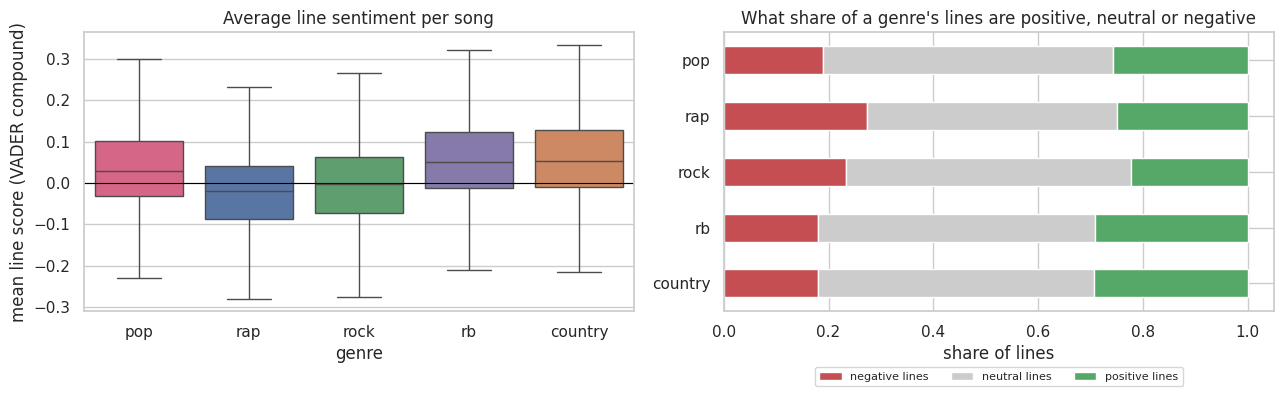

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.boxplot(data=scores, x="tag", y="vader_mean", order=GENRES, hue="tag", hue_order=GENRES, palette=GENRE_COLORS,
            legend=False, showfliers=False, ax=axes[0])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(title="Average line sentiment per song", xlabel="genre", ylabel="mean line score (VADER compound)")

shares = genre_summary[["negative lines", "neutral lines", "positive lines"]]
shares.plot.barh(stacked=True, color=["#c44e52", "#cccccc", "#55a868"], ax=axes[1])
axes[1].set(title="What share of a genre's lines are positive, neutral or negative", xlabel="share of lines", ylabel="")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**What we see.** Country (median 0.054) and rb (0.050) are the most positive genres, pop is in the middle (0.030), rock is
essentially neutral (-0.003) and rap is the only genre whose typical song is negative (-0.019). The bootstrap intervals
are narrow and only rb and country overlap. The line shares tell the same story: rap has the highest share of negative
lines (27.4%) and the lowest share of neutral ones, and 37.7% of rap songs are negative overall, against 14.4% of
country songs. TextBlob ranks the genres the same way, with rap lowest (0.014) and rb and country highest (0.100).

Notice how small all these numbers are. About half of the lines in every genre are neutral, so even a "positive genre" is
only slightly positive on average.

**Are the differences real, and are they big?** The Kruskal-Wallis test checks whether at least one genre differs from
the others, and **epsilon squared** (ε²) tells us how much of the variation in sentiment is explained by genre
(0 = nothing, 1 = everything). Then every pair of genres is compared with a Mann-Whitney test, with p-values corrected
for running 10 tests (Holm), and with **Cliff's delta** as effect size: the probability that a random song from the
first genre is more positive than a random song from the second, minus the reverse. Delta goes from -1 to 1 and
0 means no difference. Theory for these methods is in Annexes B–D (notebook 5).

Kruskal-Wallis H = 3069.2, p = 0.0e+00, epsilon squared = 0.079


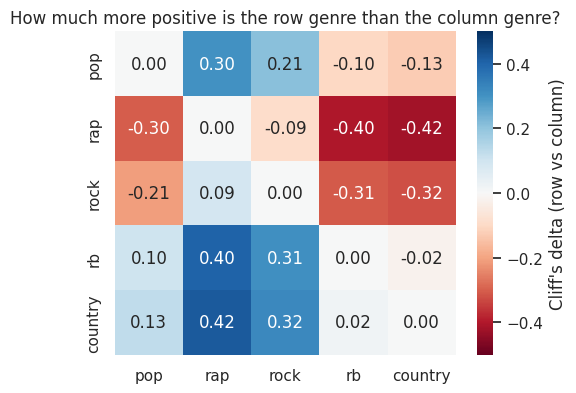

,group_1,group_2,p_value,cliffs_delta,size,p_holm
0,pop,rap,0.000,0.304,small,9.0e-297
1,pop,rock,0.000,0.207,small,1.7e-139
2,pop,rb,0.000,-0.105,negligible,1.6e-28
3,pop,country,0.000,-0.125,negligible,1.2e-27
4,rap,rock,0.000,-0.093,negligible,9.1e-29
5,rap,rb,0.000,-0.403,medium,0.0e+00
6,rap,country,0.000,-0.419,medium,1.8e-292
7,rock,rb,0.000,-0.307,small,4.9e-233
8,rock,country,0.000,-0.324,small,7.5e-176
9,rb,country,0.079,-0.022,negligible,7.9e-02


In [12]:
groups = {genre: scores.loc[scores["tag"] == genre, "vader_mean"].values for genre in GENRES}
kw = stats.kruskal_epsilon2(groups)
print(f"Kruskal-Wallis H = {kw['H']:.1f}, p = {kw['p_value']:.1e}, epsilon squared = {kw['epsilon2']:.3f}")

pairs = stats.pairwise_mannwhitney(groups)

delta_matrix = pd.DataFrame(0.0, index=GENRES, columns=GENRES)
for _, r in pairs.iterrows():
    delta_matrix.loc[r["group_1"], r["group_2"]] = r["cliffs_delta"]
    delta_matrix.loc[r["group_2"], r["group_1"]] = -r["cliffs_delta"]

plt.figure(figsize=(5.5, 4.2))
sns.heatmap(delta_matrix, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-0.5, vmax=0.5,
            cbar_kws={"label": "Cliff's delta (row vs column)"})
plt.title("How much more positive is the row genre than the column genre?")
plt.show()
pairs.assign(p_holm=pairs["p_holm"].map("{:.1e}".format)).round(3)

**What we see.** Genre explains only about 8% of the variation in song sentiment (ε² = 0.079). Every pair of genres
differs significantly except rb and country (Holm-adjusted p = 0.079), but with around 10,000 songs per genre almost any
difference is significant, so the size of the difference is what we read:

- rap vs rb (δ = -0.403) and rap vs country (δ = -0.419) are **medium** effects: a random rap song is less positive than a
  random country song much more often than the other way round.
- pop vs rap (0.304), rock vs rb (-0.307) and rock vs country (-0.324) are **small** effects.
- rap vs rock (-0.093), pop vs rb (-0.105) and pop vs country (-0.125) are **negligible**.

**What it means → hypothesis.** The hypothesis that rap and rock are the most negative genres is **supported**: they are
the two lowest, close to each other, and clearly below country and rb. The bigger lesson, though, is how much the genres
overlap. Knowing a song's genre tells us very little about the mood of that particular song.

## 4. SQ2 — How much of this is just swearing?

VADER's lexicon gives negative scores to swear words and slurs (for example *shit* = -2.6, *bitch* = -2.8 and even
*niggas* = -1.4). In rap these words are often used as filler, emphasis or in-group address rather than to express a
negative feeling, so rap may look negative partly because of vocabulary rather than mood. The data exploration already
showed rap has its own vocabulary, so this is worth testing directly.

**How:** we make a second VADER analyzer with those words removed from its lexicon, so they count as neutral, and score
the same songs again. Nothing else in VADER changes. Lines without any of these words keep exactly the same score, so only
lines that contain one are re-scored. The word list is `sentiment.PROFANITY` in `src/sentiment.py`; it only contains
words that are actually in VADER's lexicon.

In [13]:
no_profanity = sentiment.vader_analyzer(drop_words=sentiment.PROFANITY)
clean_cache = {line: s for line, s in line_cache.items() if not sentiment.PROFANITY_RE.search(line)}

scores["vader_mean_no_profanity"] = sentiment.vader_song_scores(sample["raw_text"], no_profanity, clean_cache)["vader_mean"]
scores["profane_lines"] = sentiment.profane_line_share(sample["raw_text"])

profanity = scores.groupby("tag").agg(
    profane_lines=("profane_lines", "mean"),
    median_with=("vader_mean", "median"),
    median_without=("vader_mean_no_profanity", "median"),
    negative_songs_with=("vader_mean", lambda s: (s <= config.VADER_NEG).mean()),
    negative_songs_without=("vader_mean_no_profanity", lambda s: (s <= config.VADER_NEG).mean()),
).loc[GENRES]
profanity["median change"] = profanity["median_without"] - profanity["median_with"]

rap, pop = scores["tag"] == "rap", scores["tag"] == "pop"
print("Cliff's delta, rap vs pop, with profanity:    "
      f"{stats.cliffs_delta(scores.loc[rap, 'vader_mean'], scores.loc[pop, 'vader_mean']):.3f}")
print("Cliff's delta, rap vs pop, without profanity: "
      f"{stats.cliffs_delta(scores.loc[rap, 'vader_mean_no_profanity'], scores.loc[pop, 'vader_mean_no_profanity']):.3f}")
profanity.round(3)

Cliff's delta, rap vs pop, with profanity:    -0.304
Cliff's delta, rap vs pop, without profanity: -0.076


,profane_lines,median_with,median_without,negative_songs_with,negative_songs_without,median change
tag,,,,,,
pop,0.012,0.030,0.034,0.195,0.177,0.004
rap,0.119,-0.019,0.025,0.377,0.153,0.045
rock,0.014,-0.003,0.001,0.321,0.296,0.004
rb,0.028,0.050,0.060,0.151,0.115,0.010
country,0.009,0.054,0.057,0.144,0.133,0.003


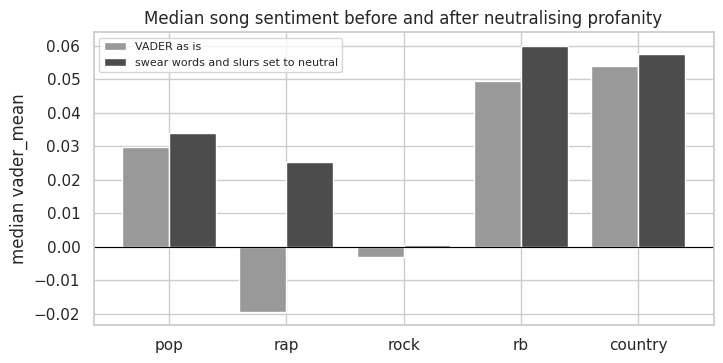

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(GENRES))
ax.bar(x - 0.2, profanity["median_with"], width=0.4, label="VADER as is", color="#999999")
ax.bar(x + 0.2, profanity["median_without"], width=0.4, label="swear words and slurs set to neutral", color="#4c4c4c")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, GENRES)
ax.set(title="Median song sentiment before and after neutralising profanity", ylabel="median vader_mean")
ax.legend(fontsize=8)
plt.show()

**What we see.** About 12% of rap lines (0.119) contain a word from the list, against 1–3% in the other genres. Treating
those words as neutral moves rap's median from -0.019 to +0.025 and cuts the share of negative rap songs from 37.7% to
15.3%. The other genres hardly move (their medians change by 0.003 to 0.010). The rap vs pop difference shrinks from a
small effect (Cliff's delta -0.304) to a negligible one (-0.076).

**What it means → hypothesis.** Most of rap's negativity comes from vocabulary that VADER's lexicon labels as negative,
not from negative statements. Once swearing is neutralised, rap is about as positive as pop, and **rock becomes the least
positive genre** (median 0.001). This supports our SQ2 hypothesis and changes how SQ1 should be read: "rap is the most
negative genre" is largely a lexicon effect.

We still report both versions, because neither is the full truth. Some of these words *are* aggressive in context, and a
lexicon cannot tell an insult from filler.

## 5. SQ3 — Has sentiment changed over the decades?

In notebook 1 we saw that release years are unreliable before 1900 (placeholders like year 1, and poems or plays from
centuries ago) and that only a small part of the songs is older than the 1980s. Notebook 2 already set years before 1900
to missing (`year_clean`). Here we keep songs from **1960 onwards** and only use a genre–decade combination if it has at
least **100 songs**, so a median is never computed on a handful of songs.

We measure the trend in two ways:

- the median sentiment per decade with its bootstrap 95% interval (the figure);
- the Spearman correlation between release year and `vader_mean` inside each genre, with a bootstrap interval
  (positive = lyrics became more positive over time).

In [15]:
MIN_SONGS_PER_CELL = 100

timed = scores.dropna(subset=["year_clean"])
timed = timed[timed["year_clean"] >= 1960].assign(decade=lambda d: (d["year_clean"] // 10 * 10).astype(int))
cell_size = timed.groupby(["tag", "decade"]).size()
kept_cells = cell_size[cell_size >= MIN_SONGS_PER_CELL].index
timed = timed.set_index(["tag", "decade"]).loc[kept_cells].reset_index()

decade_rows = []
for (genre, decade), g in timed.groupby(["tag", "decade"]):
    low, high = stats.bootstrap_ci(g["vader_mean"], np.median, n_boot=500, seed=config.SEED)
    decade_rows.append({"genre": genre, "decade": decade, "songs": len(g),
                        "median": g["vader_mean"].median(), "low": low, "high": high})
by_decade = pd.DataFrame(decade_rows)
print("Songs per genre and decade (cells with fewer than 100 songs are left out):")
by_decade.pivot(index="decade", columns="genre", values="songs")[[g for g in GENRES if g in set(by_decade["genre"])]]

Songs per genre and decade (cells with fewer than 100 songs are left out):


genre,pop,rap,rock,rb,country
decade,,,,,
1960,151.0,NaN,101.0,146.0,263.0
1970,231.0,NaN,256.0,273.0,292.0
1980,388.0,NaN,410.0,177.0,166.0
1990,930.0,223.0,812.0,276.0,287.0
2000,1988.0,556.0,1467.0,321.0,412.0
2010,4305.0,5901.0,5054.0,2993.0,1368.0
2020,1781.0,3032.0,1758.0,1893.0,526.0


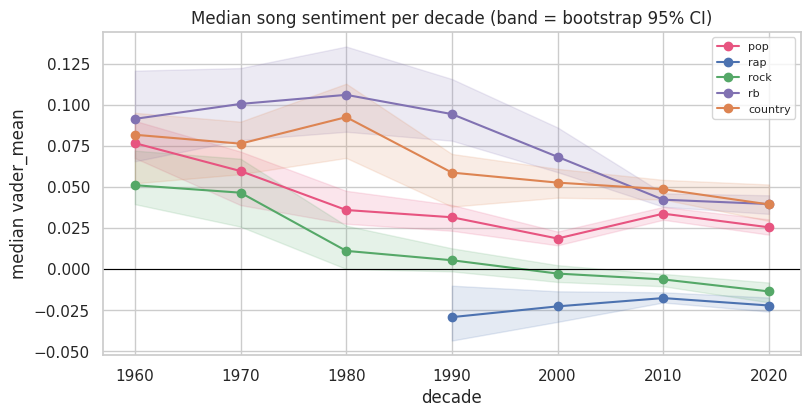

Median vader_mean per decade:
genre     pop    rap   rock     rb  country
decade                                     
1960    0.077    NaN  0.051  0.091    0.082
1970    0.060    NaN  0.047  0.101    0.076
1980    0.036    NaN  0.011  0.106    0.093
1990    0.032 -0.029  0.005  0.094    0.059
2000    0.019 -0.023 -0.003  0.068    0.053
2010    0.034 -0.018 -0.006  0.042    0.049
2020    0.025 -0.022 -0.014  0.040    0.039


,rho,ci_low,ci_high,p_value,n
genre,,,,,
pop,-0.008,-0.027,0.012,0.451,9774
rap,-0.012,-0.032,0.010,0.248,9712
rock,-0.081,-0.100,-0.062,0.000,9858
rb,-0.158,-0.184,-0.133,0.000,6079
country,-0.097,-0.130,-0.064,0.000,3314


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for genre in GENRES:
    g = by_decade[by_decade["genre"] == genre]
    if g.empty:
        continue
    ax.plot(g["decade"], g["median"], marker="o", color=GENRE_COLORS[genre], label=genre)
    ax.fill_between(g["decade"], g["low"], g["high"], color=GENRE_COLORS[genre], alpha=0.15)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Median song sentiment per decade (band = bootstrap 95% CI)", xlabel="decade", ylabel="median vader_mean")
ax.legend(fontsize=8)
plt.show()
print("Median vader_mean per decade:")
print(by_decade.pivot(index="decade", columns="genre", values="median")[[g for g in GENRES if g in set(by_decade["genre"])]].round(3))

trend_rows = []
for genre, g in timed.groupby("tag"):
    r = stats.spearman_ci(g["year_clean"], g["vader_mean"], n_boot=500, seed=config.SEED)
    trend_rows.append({"genre": genre, **r})
trend = pd.DataFrame(trend_rows).set_index("genre").loc[[g for g in GENRES if g in set(timed["tag"])]]
trend.round(3)

**What we see.** Looking at the medians per decade, every genre except rap was more positive in the 1960s than it is
today: rb goes from 0.091 to 0.040, country from 0.082 to 0.039, pop from 0.077 to 0.025 and rock from 0.051 to -0.014.
Rap, which only has enough songs from the 1990s on, stays negative and flat (-0.029 in the 1990s, -0.022 in the 2020s).

The year-by-year correlations tell a more careful story. Rock (ρ = -0.081), country (-0.097) and especially rb (-0.158)
show a steady decline, with intervals that stay below zero. Pop's correlation is practically zero (-0.008), because most
pop songs in the data are from the 2000s onwards, and from then on pop's median hardly moves (between 0.019 and 0.034).
Pop's decline happened before 2000, among relatively few songs.

**What it means → hypothesis.** The hypothesis that lyrics became more negative over time (DeWall et al., 2011; Brand et
al., 2019) is **partly supported**. The direction is right for every genre with enough old songs, but the change is small
(|ρ| ≤ 0.16) and, for pop, limited to the older decades. Rap does not change.

Two cautions when reading this:

- The older decades are much smaller in our data, and the old songs that end up on a lyrics website are mostly the
  well-known classics. "The 1970s" here really means "the 1970s songs people still look up", not a random sample of what
  was released.
- Rap only reaches 100 songs per decade from the 1990s on, so its trend covers a shorter period than the others.

## 6. SQ4 — Are more positive songs more popular?

`views` counts page views on the lyrics website, not sales or streams, and it is extremely skewed (notebook 1), so we
work with `log_views` and rank-based correlations. There is also a trap: older songs have had more years to collect
views, and in SQ3 we saw that sentiment changes with release year too. A raw correlation between sentiment and views
could then just be the year talking.

So we compare each song only with songs **of the same genre released in the same year**: `views_rank_in_year` is the
song's percentile of views within its genre and year (0 = fewest views, 1 = most). Year–genre groups with fewer than
20 songs are left out because a percentile inside a tiny group is meaningless.

In [17]:
popular = scores.dropna(subset=["year_clean"]).copy()
group_size = popular.groupby(["tag", "year_clean"])["id"].transform("size")
popular = popular[group_size >= 20]
popular["views_rank_in_year"] = popular.groupby(["tag", "year_clean"])["views"].rank(pct=True)

pop_rows = []
for genre in GENRES:
    g = popular[popular["tag"] == genre]
    raw = stats.spearman_ci(g["vader_mean"], g["log_views"], n_boot=500, seed=config.SEED)
    within = stats.spearman_ci(g["vader_mean"], g["views_rank_in_year"], n_boot=500, seed=config.SEED)
    pop_rows.append({"genre": genre, "songs": len(g),
                     "rho with log views": raw["rho"], "CI (raw)": f"[{raw['ci_low']:.3f}, {raw['ci_high']:.3f}]",
                     "rho with views rank in year": within["rho"],
                     "CI (within year)": f"[{within['ci_low']:.3f}, {within['ci_high']:.3f}]"})
popularity = pd.DataFrame(pop_rows).set_index("genre")
popularity.round(3)

,songs,rho with log views,CI (raw),rho with views rank in year,CI (within year)
genre,,,,,
pop,9639,0.070,"[0.050, 0.090]",0.073,"[0.052, 0.092]"
rap,9661,-0.052,"[-0.070, -0.030]",-0.059,"[-0.079, -0.039]"
rock,9792,0.097,"[0.077, 0.116]",0.079,"[0.059, 0.097]"
rb,5906,0.038,"[0.012, 0.062]",0.004,"[-0.023, 0.029]"
country,3142,-0.019,"[-0.054, 0.014]",-0.018,"[-0.054, 0.016]"


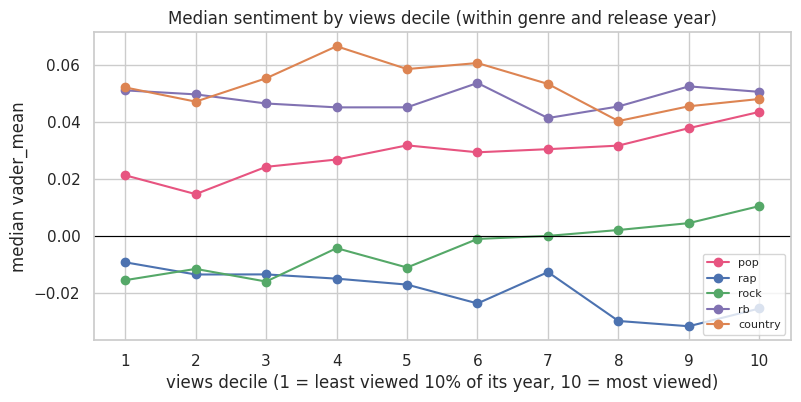

In [18]:
popular["views_decile"] = np.minimum((popular["views_rank_in_year"] * 10).astype(int), 9) + 1
fig, ax = plt.subplots(figsize=(9, 4))
for genre in GENRES:
    g = popular[popular["tag"] == genre].groupby("views_decile")["vader_mean"].median()
    ax.plot(g.index, g.values, marker="o", color=GENRE_COLORS[genre], label=genre)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Median sentiment by views decile (within genre and release year)",
       xlabel="views decile (1 = least viewed 10% of its year, 10 = most viewed)", ylabel="median vader_mean")
ax.set_xticks(range(1, 11))
ax.legend(fontsize=8)
plt.show()

**What we see.** Every correlation between sentiment and views is very weak (all |ρ| < 0.1). Within its own year, a more
positive pop or rock song is very slightly more viewed (ρ = 0.073 and 0.079), a more positive rap song very slightly less
(-0.059), and rb and country show no relation (both intervals include 0). Controlling for release year hardly changes
the numbers, so the year was not what drove them. In the decile figure, pop and rock creep up slightly from the least to
the most viewed songs and rap creeps down, but the whole movement is a few hundredths on a scale from -1 to 1.

**What it means.** In this data sentiment and popularity are practically unrelated. Whatever makes a song popular, it
isn't the emotional tone of its lyrics. The opposite signs for rap (darker songs do marginally better) and pop/rock
(brighter songs do marginally better) are interesting but too small to build on. These are correlations only: nothing
here says that changing a song's mood would change its views.

## 7. SQ5 — Is the chorus more positive than the verses?

Here every song is compared **with itself**: we score the chorus/hook/refrain lines and the verse lines of the same song
separately and look at the difference (chorus minus verse). Comparing a song with itself removes everything that differs
between songs (artist, era, topic), which makes this the cleanest comparison in the notebook.

Only songs that have both a chorus-type tag and a verse tag can be used. Notebook 1 showed that only about half of the
songs have section tags at all, and the table below shows that this share differs a lot between genres, so this subset is
not a random part of each genre. We keep that in mind when reading the results. The test is the **Wilcoxon signed-rank test** for paired data (Annex E, notebook 5); as effect size we report the
median difference and the share of songs whose chorus is more positive than their verses.

In [19]:
tagged = sample[(sample["chorus_text"].str.strip() != "") & (sample["verse_text"].str.strip() != "")]
chorus = sentiment.vader_song_scores(tagged["chorus_text"], analyzer, line_cache)["vader_mean"]
verse = sentiment.vader_song_scores(tagged["verse_text"], analyzer, line_cache)["vader_mean"]
paired = pd.DataFrame({"tag": tagged["tag"], "chorus": chorus, "verse": verse}).dropna()
paired["difference"] = paired["chorus"] - paired["verse"]

section_rows = []
for genre in GENRES:
    g = paired[paired["tag"] == genre]
    low, high = stats.bootstrap_ci(g["difference"], np.median, seed=config.SEED)
    section_rows.append({
        "genre": genre,
        "songs with both": len(g),
        "share of the genre's sampled songs": len(g) / (sample["tag"] == genre).sum(),
        "median chorus - verse": g["difference"].median(),
        "95% CI": f"[{low:.3f}, {high:.3f}]",
        "chorus more positive": (g["difference"] > 0).mean(),
        "verse more positive": (g["difference"] < 0).mean(),
        "Wilcoxon p": sps.wilcoxon(g["chorus"], g["verse"]).pvalue,
    })
sections = pd.DataFrame(section_rows).set_index("genre")
sections.round(3)

,songs with both,share of the genre's sampled songs,median chorus - verse,95% CI,chorus more positive,verse more positive,Wilcoxon p
genre,,,,,,,
pop,2508,0.255,0.013,"[0.006, 0.022]",0.537,0.459,0.000
rap,4764,0.489,0.009,"[0.003, 0.015]",0.519,0.480,0.002
rock,3136,0.318,0.011,"[0.006, 0.017]",0.533,0.464,0.000
rb,3261,0.532,0.014,"[0.007, 0.020]",0.537,0.461,0.000
country,1456,0.423,0.007,"[-0.004, 0.017]",0.519,0.480,0.076


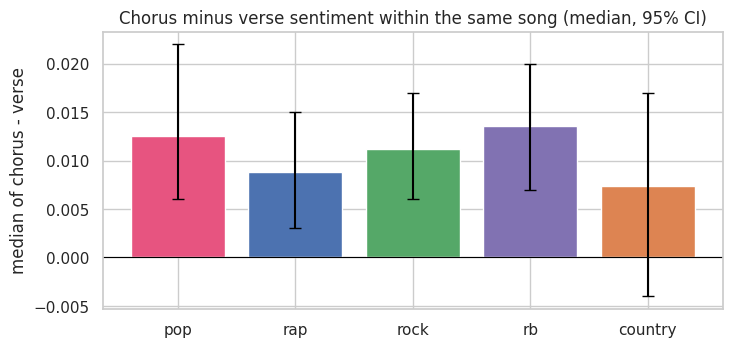

In [20]:
medians = sections["median chorus - verse"]
ci = sections["95% CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(GENRES, medians, color=PALETTE)
ax.errorbar(GENRES, medians, yerr=[medians - ci[0], ci[1] - medians], fmt="none", ecolor="black", capsize=4)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Chorus minus verse sentiment within the same song (median, 95% CI)",
       ylabel="median of chorus - verse")
plt.show()

**What we see.** In every genre the chorus is slightly more positive than the verses of the same song. The median
difference is about +0.01 (from 0.007 in country to 0.014 in rb), and the chorus is the more positive part in 52–54% of
songs. The difference is significant in every genre except country (p = 0.076), but it is small: roughly half the gap
between the medians of pop and country.

Only about a quarter of pop songs (25.5%) and a third of rock songs (31.8%) have both tags, against about half of rap and
rb songs. So for pop and rock this result describes the more "structured" songs of the genre.

**What it means → hypothesis.** The hypothesis is **supported in direction, but the effect is weak**. Choruses lean a
little more positive, which fits the idea that the hook carries the song's main message, but chorus and verses are
emotionally far more alike than different.

## 8. Findings in one table

The table below collects the main number behind each answer. It is saved to `results/sentiment_findings.csv` so the
Conclusion (notebook 5) quotes exactly these values.

In [21]:
most_negative = genre_summary["median vader_mean"].idxmin()
most_positive = genre_summary["median vader_mean"].idxmax()
rap_pop_with = stats.cliffs_delta(scores.loc[rap, "vader_mean"], scores.loc[pop, "vader_mean"])
rap_pop_without = stats.cliffs_delta(scores.loc[rap, "vader_mean_no_profanity"], scores.loc[pop, "vader_mean_no_profanity"])

findings = pd.DataFrame([
    {"question": "Method check", "measure": "Spearman, VADER (per line) vs TextBlob, all songs",
     "value": agreement.loc["all", "VADER vs TextBlob (Spearman)"]},
    {"question": "SQ1 genre", "measure": f"most negative genre ({most_negative}), median vader_mean",
     "value": genre_summary.loc[most_negative, "median vader_mean"]},
    {"question": "SQ1 genre", "measure": f"most positive genre ({most_positive}), median vader_mean",
     "value": genre_summary.loc[most_positive, "median vader_mean"]},
    {"question": "SQ1 genre", "measure": "epsilon squared (share of sentiment variation explained by genre)",
     "value": kw["epsilon2"]},
    {"question": "SQ2 profanity", "measure": "Cliff's delta rap vs pop, VADER as is", "value": rap_pop_with},
    {"question": "SQ2 profanity", "measure": "Cliff's delta rap vs pop, profanity neutral", "value": rap_pop_without},
    *[{"question": "SQ3 time", "measure": f"Spearman year vs sentiment, {g}", "value": trend.loc[g, "rho"]}
      for g in trend.index],
    *[{"question": "SQ4 popularity", "measure": f"Spearman sentiment vs views rank in year, {g}",
       "value": popularity.loc[g, "rho with views rank in year"]} for g in GENRES],
    *[{"question": "SQ5 chorus", "measure": f"median chorus - verse, {g}",
       "value": sections.loc[g, "median chorus - verse"]} for g in GENRES],
])
findings["value"] = findings["value"].round(3)
findings.to_csv(config.SENTIMENT_FINDINGS, index=False, encoding=config.ENCODING)
print(f"Notebook runtime: {(time.time() - notebook_start) / 60:.1f} min")
findings

Notebook runtime: 3.1 min


,question,measure,value
0,Method check,"Spearman, VADER (per line) vs TextBlob, all songs",0.563
1,SQ1 genre,"most negative genre (rap), median vader_mean",-0.019
2,SQ1 genre,"most positive genre (country), median vader_mean",0.054
3,SQ1 genre,epsilon squared (share of sentiment variation explained by genre),0.079
4,SQ2 profanity,"Cliff's delta rap vs pop, VADER as is",-0.304
5,SQ2 profanity,"Cliff's delta rap vs pop, profanity neutral",-0.076
6,SQ3 time,"Spearman year vs sentiment, pop",-0.008
7,SQ3 time,"Spearman year vs sentiment, rap",-0.012
8,SQ3 time,"Spearman year vs sentiment, rock",-0.081
9,SQ3 time,"Spearman year vs sentiment, rb",-0.158


## Key takeaways → next notebook

- VADER scored **line by line** is a usable sentiment measure for lyrics. Scored on whole songs it saturates (two thirds
  of songs beyond ±0.9). It agrees moderately with TextBlob (ρ = 0.56), and its blind spots are slang and swearing.
- **Country and rb are the most positive genres, rap and rock the least**, but genre explains only about 8% of the
  variation: the genres overlap a lot.
- **Rap's negativity is mostly swearing.** With profanity treated as neutral, rap moves next to pop and rock becomes the
  least positive genre.
- **Most genres were more positive in the 1960s than today**, but the change is small: steady in rock, country and rb,
  limited to the years before 2000 in pop, and absent in rap.
- **Sentiment is practically unrelated to views**, even when songs are compared only with songs from the same year.
- **Choruses are slightly more positive than verses** in every genre, but the difference is small.

Notebook 5 brings these results together with the genre classification and checks them against our hypotheses.